# Modelo RNN simple

En este notebook se entrena una red neuronal recurrente simple (SimpleRNN) para clasificar el género musical a partir de df_macro.

Las RNN son adecuadas cuando el orden temporal importa. En este dataset el género se manifiesta a lo largo de la pista: df_macro contiene ventanas sucesivas de 3 s de cada canción, y la RNN simple las lee en ese orden. En cada paso actualiza un estado oculto con el fragmento actual y el estado del paso anterior. Las features de 30 s se descartan: son un resumen estático de todo el tema y, si se repiten en cada paso, la red deja de modelar la secuencia.

A diferencia de una ANN sobre un único vector de 30 s, aquí cada canción es una secuencia de fragmentos de 3 s y se predice un género por id_cancion.

Respecto a la GRU del grupo (también a nivel canción y con fragmentos de 3 s): se parte de df_macro en lugar del csv solo de 3 s, no se usan columnas *_30s y la arquitectura es dos capas SimpleRNN apiladas, frente a una sola GRU. La celda recurrente es una RNN simple, distinta de la LSTM y de la GRU.

## Problema y objetivos

La empresa quiere identificar el género de una canción a partir de sus características de audio. La variable `id_genero` no es una etiqueta de sí o no, ni un valor numérico a estimar: toma 10 valores distintos y cada canción pertenece a una sola clase. El problema es de **clasificación supervisada multiclase**.

En este notebook el objetivo es entrenar una RNN simple que lea, en orden temporal, los fragmentos de 3 segundos de cada canción y le asigne una de esas 10 clases. El modelo se ajusta solo con las canciones de entrenamiento; el conjunto de test se reserva para la evaluación. El resultado se mide con accuracy y F1 macro, para ver el acierto global y el rendimiento medio entre géneros.

## Selección de métricas y umbral

**Accuracy.** Hay 10 géneros y el mismo número de canciones en cada clase. Con ese reparto equilibrado, el porcentaje de aciertos resume el rendimiento global sin que una clase más frecuente lo distorsione.

**F1 macro.** Se calcula el F1 de cada género y se promedia dando el mismo peso a las 10 clases. Así, un género fácil de clasificar no compensa a otro que el modelo confunde. El F1 por clase del informe de clasificación muestra cuáles son esos géneros.

**Umbral de decisión.** El modelo devuelve una probabilidad para cada una de las 10 clases. La clase asignada es la de probabilidad más alta. No se exige una probabilidad mínima para aceptar la predicción: si la clase ganadora tiene, por ejemplo, 0,2 y el resto queda por debajo, esa clase se predice igualmente.

In [1]:
import re
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

random.seed(42)
np.random.seed(42)
tf.random.set_seed(42)

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.layers import Dense, Dropout, Input, SimpleRNN, Masking
from tensorflow.keras.models import Sequential
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Carga y preparación de los datos

In [2]:
from pathlib import Path

def carpeta_proyecto(nombre, marca):
    """Localiza los CSV en Jupyter, Visual Studio Code y Colab."""
    from pathlib import Path
    import json

    saltar = {
        ".config", "sample_data", "drive", ".git", "__pycache__",
        "node_modules", ".ipynb_checkpoints", "site-packages",
    }

    def directorio_notebook():
        try:
            return Path(__vsc_ipynb_file__).resolve().parent
        except NameError:
            pass
        try:
            from urllib.request import urlopen
            try:
                from ipykernel.connect import get_connection_file
            except ImportError:
                from ipykernel import get_connection_file
            conexion = Path(get_connection_file())
            kernel_id = conexion.name.replace("kernel-", "").replace(".json", "")
            servidores = list(conexion.parent.glob("jpserver-*.json"))[:3]
            for servidor in servidores:
                try:
                    info = json.loads(servidor.read_text(encoding="utf-8"))
                except (OSError, json.JSONDecodeError):
                    continue
                url = str(info.get("url", "")).rstrip("/")
                raiz = info.get("root_dir")
                if not url or not raiz:
                    continue
                api = url + "/api/sessions"
                token = info.get("token") or ""
                if token:
                    api += "?token=" + token
                try:
                    with urlopen(api, timeout=0.8) as respuesta:
                        sesiones = json.loads(respuesta.read().decode())
                except Exception:
                    continue
                for sesion in sesiones:
                    kid = (sesion.get("kernel") or {}).get("id")
                    if kid != kernel_id:
                        continue
                    cuaderno = sesion.get("notebook") or {}
                    relativo = cuaderno.get("path") or sesion.get("path")
                    if relativo:
                        return (Path(raiz) / relativo).resolve().parent
        except Exception:
            pass
        return None

    bases = []
    notebook = directorio_notebook()
    if notebook is not None:
        bases.append(notebook)
    bases.append(Path.cwd().resolve())
    content = Path("/content")
    if content.is_dir():
        bases.append(content)
        drive = content / "drive" / "MyDrive"
        if drive.is_dir():
            bases.append(drive)

    nombradas = []
    sueltas = []
    vistos = set()

    def considerar(directorio, aceptar_suelto):
        if directorio in vistos:
            return
        vistos.add(directorio)
        try:
            carpeta = directorio / nombre
            if (carpeta / marca).is_file():
                nombradas.append(carpeta)
                return
            if directorio.name == nombre and (directorio / marca).is_file():
                nombradas.append(directorio)
                return
            if aceptar_suelto and (directorio / marca).is_file():
                sueltas.append(directorio)
        except OSError:
            return

    def hijos(directorio, profundidad, limite):
        if profundidad < 0 or limite[0] <= 0 or not directorio.is_dir():
            return
        try:
            entradas = list(directorio.iterdir())
        except OSError:
            return
        for hijo in entradas:
            if not hijo.is_dir() or hijo.name.startswith(".") or hijo.name in saltar:
                continue
            limite[0] -= 1
            considerar(hijo, False)
            if nombradas or limite[0] <= 0:
                return
            hijos(hijo, profundidad - 1, limite)
            if nombradas or limite[0] <= 0:
                return

    for base in bases:
        considerar(base, True)
        if nombradas:
            break
        for padre in list(base.parents)[:6]:
            considerar(padre, False)
            if nombradas:
                break
        if nombradas:
            break
        profundidad = 3 if base.name in {"content", "MyDrive"} else 2
        hijos(base, profundidad, [400])
        if nombradas:
            break

    if nombradas:
        return nombradas[0]
    if sueltas:
        return sueltas[0]
    raise FileNotFoundError(
        "No se encuentra " + marca + ". "
        "Tiene que existir la carpeta '" + nombre + "' en el proyecto, "
        "o el archivo en el directorio de trabajo. En Colab puede estar junto a sample_data."
    )


def carpeta_datos():
    """Carpeta datos preprocesados, en Jupyter, Visual Studio Code o Colab."""
    return carpeta_proyecto("datos preprocesados", "ids_train.csv")

DATOS = carpeta_datos()
print("Datos:", DATOS)

# Cargar df_macro: fragmentos de 3 s unidos a las features de 30 s y a los ids.
df_macro = pd.read_csv(DATOS / "df_macro.csv")
display(df_macro.head())
print("Dimensiones:", df_macro.shape)

,id_cancion,filename_3s,length_3s,chroma_stft_mean_3s,chroma_stft_var_3s,rms_mean_3s,rms_var_3s,spectral_centroid_mean_3s,spectral_centroid_var_3s,spectral_bandwidth_mean_3s,...,mfcc16_var_30s,mfcc17_mean_30s,mfcc17_var_30s,mfcc18_mean_30s,mfcc18_var_30s,mfcc19_mean_30s,mfcc19_var_30s,mfcc20_mean_30s,mfcc20_var_30s,label_30s
0,1,blues.00000.0.wav,66149,0.335406,0.091048,0.130405,0.003521,1773.065032,167541.630869,1972.744388,...,52.42091,-1.690215,36.524071,-0.408979,41.597103,-2.303523,55.062923,1.221291,46.936035,blues
1,1,blues.00000.1.wav,66149,0.343065,0.086147,0.112699,0.001450,1816.693777,90525.690866,2010.051501,...,52.42091,-1.690215,36.524071,-0.408979,41.597103,-2.303523,55.062923,1.221291,46.936035,blues
2,1,blues.00000.2.wav,66149,0.346815,0.092243,0.132003,0.004620,1788.539719,111407.437613,2084.565132,...,52.42091,-1.690215,36.524071,-0.408979,41.597103,-2.303523,55.062923,1.221291,46.936035,blues
3,1,blues.00000.3.wav,66149,0.363639,0.086856,0.132565,0.002448,1655.289045,111952.284517,1960.039988,...,52.42091,-1.690215,36.524071,-0.408979,41.597103,-2.303523,55.062923,1.221291,46.936035,blues
4,1,blues.00000.4.wav,66149,0.335579,0.088129,0.143289,0.001701,1630.656199,79667.267654,1948.503884,...,52.42091,-1.690215,36.524071,-0.408979,41.597103,-2.303523,55.062923,1.221291,46.936035,blues


Dimensiones: (9990, 129)


In [3]:
# Número de valores nulos por columna. Si no hay, la serie queda vacía.
nulos = df_macro.isna().sum()
nulos_con_faltas = nulos[nulos > 0].sort_values(ascending=False)

print("Total de nulos en el dataframe:", int(nulos.sum()))
if nulos_con_faltas.empty:
    print("No hay valores nulos en ninguna columna.")
else:
    display(nulos_con_faltas)

Total de nulos en el dataframe: 180


,0
duracion,180


In [4]:
from pathlib import Path

def carpeta_proyecto(nombre, marca):
    """Localiza los CSV en Jupyter, Visual Studio Code y Colab."""
    from pathlib import Path
    import json

    saltar = {
        ".config", "sample_data", "drive", ".git", "__pycache__",
        "node_modules", ".ipynb_checkpoints", "site-packages",
    }

    def directorio_notebook():
        try:
            return Path(__vsc_ipynb_file__).resolve().parent
        except NameError:
            pass
        try:
            from urllib.request import urlopen
            try:
                from ipykernel.connect import get_connection_file
            except ImportError:
                from ipykernel import get_connection_file
            conexion = Path(get_connection_file())
            kernel_id = conexion.name.replace("kernel-", "").replace(".json", "")
            servidores = list(conexion.parent.glob("jpserver-*.json"))[:3]
            for servidor in servidores:
                try:
                    info = json.loads(servidor.read_text(encoding="utf-8"))
                except (OSError, json.JSONDecodeError):
                    continue
                url = str(info.get("url", "")).rstrip("/")
                raiz = info.get("root_dir")
                if not url or not raiz:
                    continue
                api = url + "/api/sessions"
                token = info.get("token") or ""
                if token:
                    api += "?token=" + token
                try:
                    with urlopen(api, timeout=0.8) as respuesta:
                        sesiones = json.loads(respuesta.read().decode())
                except Exception:
                    continue
                for sesion in sesiones:
                    kid = (sesion.get("kernel") or {}).get("id")
                    if kid != kernel_id:
                        continue
                    cuaderno = sesion.get("notebook") or {}
                    relativo = cuaderno.get("path") or sesion.get("path")
                    if relativo:
                        return (Path(raiz) / relativo).resolve().parent
        except Exception:
            pass
        return None

    bases = []
    notebook = directorio_notebook()
    if notebook is not None:
        bases.append(notebook)
    bases.append(Path.cwd().resolve())
    content = Path("/content")
    if content.is_dir():
        bases.append(content)
        drive = content / "drive" / "MyDrive"
        if drive.is_dir():
            bases.append(drive)

    nombradas = []
    sueltas = []
    vistos = set()

    def considerar(directorio, aceptar_suelto):
        if directorio in vistos:
            return
        vistos.add(directorio)
        try:
            carpeta = directorio / nombre
            if (carpeta / marca).is_file():
                nombradas.append(carpeta)
                return
            if directorio.name == nombre and (directorio / marca).is_file():
                nombradas.append(directorio)
                return
            if aceptar_suelto and (directorio / marca).is_file():
                sueltas.append(directorio)
        except OSError:
            return

    def hijos(directorio, profundidad, limite):
        if profundidad < 0 or limite[0] <= 0 or not directorio.is_dir():
            return
        try:
            entradas = list(directorio.iterdir())
        except OSError:
            return
        for hijo in entradas:
            if not hijo.is_dir() or hijo.name.startswith(".") or hijo.name in saltar:
                continue
            limite[0] -= 1
            considerar(hijo, False)
            if nombradas or limite[0] <= 0:
                return
            hijos(hijo, profundidad - 1, limite)
            if nombradas or limite[0] <= 0:
                return

    for base in bases:
        considerar(base, True)
        if nombradas:
            break
        for padre in list(base.parents)[:6]:
            considerar(padre, False)
            if nombradas:
                break
        if nombradas:
            break
        profundidad = 3 if base.name in {"content", "MyDrive"} else 2
        hijos(base, profundidad, [400])
        if nombradas:
            break

    if nombradas:
        return nombradas[0]
    if sueltas:
        return sueltas[0]
    raise FileNotFoundError(
        "No se encuentra " + marca + ". "
        "Tiene que existir la carpeta '" + nombre + "' en el proyecto, "
        "o el archivo en el directorio de trabajo. En Colab puede estar junto a sample_data."
    )


def carpeta_datos():
    """Carpeta datos preprocesados, en Jupyter, Visual Studio Code o Colab."""
    return carpeta_proyecto("datos preprocesados", "ids_train.csv")

DATOS = carpeta_datos()
print("Datos:", DATOS)

# Ids pactados por el grupo para que train/test no mezclen fragmentos de la misma canción.
ids_train = pd.read_csv(DATOS / "ids_train.csv")["id_cancion"]
ids_test = pd.read_csv(DATOS / "ids_test.csv")["id_cancion"]

In [5]:
# Split por canción (no por fila aleatoria).
df_train = df_macro[df_macro["id_cancion"].isin(ids_train)].copy()
df_test = df_macro[df_macro["id_cancion"].isin(ids_test)].copy()

print("df_train:", df_train.shape)
print("df_test:", df_test.shape)
print("Canciones train:", df_train["id_cancion"].nunique())
print("Canciones test:", df_test["id_cancion"].nunique())

df_train: (7990, 129)
df_test: (2000, 129)
Canciones train: 800
Canciones test: 200


In [6]:
# Columnas disponibles en el DataFrame de entrenamiento.
print(df_train.columns.tolist())

['id_cancion', 'filename_3s', 'length_3s', 'chroma_stft_mean_3s', 'chroma_stft_var_3s', 'rms_mean_3s', 'rms_var_3s', 'spectral_centroid_mean_3s', 'spectral_centroid_var_3s', 'spectral_bandwidth_mean_3s', 'spectral_bandwidth_var_3s', 'rolloff_mean_3s', 'rolloff_var_3s', 'zero_crossing_rate_mean_3s', 'zero_crossing_rate_var_3s', 'harmony_mean_3s', 'harmony_var_3s', 'perceptr_mean_3s', 'perceptr_var_3s', 'tempo_3s', 'mfcc1_mean_3s', 'mfcc1_var_3s', 'mfcc2_mean_3s', 'mfcc2_var_3s', 'mfcc3_mean_3s', 'mfcc3_var_3s', 'mfcc4_mean_3s', 'mfcc4_var_3s', 'mfcc5_mean_3s', 'mfcc5_var_3s', 'mfcc6_mean_3s', 'mfcc6_var_3s', 'mfcc7_mean_3s', 'mfcc7_var_3s', 'mfcc8_mean_3s', 'mfcc8_var_3s', 'mfcc9_mean_3s', 'mfcc9_var_3s', 'mfcc10_mean_3s', 'mfcc10_var_3s', 'mfcc11_mean_3s', 'mfcc11_var_3s', 'mfcc12_mean_3s', 'mfcc12_var_3s', 'mfcc13_mean_3s', 'mfcc13_var_3s', 'mfcc14_mean_3s', 'mfcc14_var_3s', 'mfcc15_mean_3s', 'mfcc15_var_3s', 'mfcc16_mean_3s', 'mfcc16_var_3s', 'mfcc17_mean_3s', 'mfcc17_var_3s', 'mfcc1

# Selección de variables

Se eliminan identificadores, texto, el target y **todas las features de 30 s**. Estas últimas son un resumen estático de toda la pista y se repetirían en cada paso de la secuencia: la RNN simple dejaría de modelar el tiempo.

También se quita length_3s (misma duración en casi todos los cortes) y duracion / coste (globales de la canción, no de la evolución del audio).

In [7]:
# length_3s no discrimina género si es constante entre fragmentos.
print(df_train["length_3s"].describe())
print("\nValores únicos:", df_train["length_3s"].nunique())

count     7990.0
mean     66149.0
std          0.0
min      66149.0
25%      66149.0
50%      66149.0
75%      66149.0
max      66149.0
Name: length_3s, dtype: float64

Valores únicos: 1


In [8]:
# Columnas que NO entran al modelo.
columnas_excluir = [
    "filename_3s",
    "length_3s",
    "label_3s",
    "cancion_base",
    "id_cancion",
    "cancion",
    "duracion",
    "coste",
    "id_genero",
    "id_disco",
    "id_autor",
    "id_discografica",
    "filename_30s",
    "label_30s",
]
# Todas las features calculadas sobre los 30 s completos.
columnas_excluir += [c for c in df_train.columns if c.endswith("_30s") and c not in columnas_excluir]

X_train = df_train.drop(columns=columnas_excluir, errors="ignore")
X_test = df_test.drop(columns=columnas_excluir, errors="ignore")
X_test = X_test[X_train.columns]

y_train = df_train["id_genero"]
y_test = df_test["id_genero"]

print("Columnas excluidas:")
print(columnas_excluir)
print("\nColumnas elegidas para el entrenamiento (", X_train.shape[1], "):", sep="")
print(X_train.columns.tolist())
print("\nX_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

Columnas excluidas:
['filename_3s', 'length_3s', 'label_3s', 'cancion_base', 'id_cancion', 'cancion', 'duracion', 'coste', 'id_genero', 'id_disco', 'id_autor', 'id_discografica', 'filename_30s', 'label_30s', 'length_30s', 'chroma_stft_mean_30s', 'chroma_stft_var_30s', 'rms_mean_30s', 'rms_var_30s', 'spectral_centroid_mean_30s', 'spectral_centroid_var_30s', 'spectral_bandwidth_mean_30s', 'spectral_bandwidth_var_30s', 'rolloff_mean_30s', 'rolloff_var_30s', 'zero_crossing_rate_mean_30s', 'zero_crossing_rate_var_30s', 'harmony_mean_30s', 'harmony_var_30s', 'perceptr_mean_30s', 'perceptr_var_30s', 'tempo_30s', 'mfcc1_mean_30s', 'mfcc1_var_30s', 'mfcc2_mean_30s', 'mfcc2_var_30s', 'mfcc3_mean_30s', 'mfcc3_var_30s', 'mfcc4_mean_30s', 'mfcc4_var_30s', 'mfcc5_mean_30s', 'mfcc5_var_30s', 'mfcc6_mean_30s', 'mfcc6_var_30s', 'mfcc7_mean_30s', 'mfcc7_var_30s', 'mfcc8_mean_30s', 'mfcc8_var_30s', 'mfcc9_mean_30s', 'mfcc9_var_30s', 'mfcc10_mean_30s', 'mfcc10_var_30s', 'mfcc11_mean_30s', 'mfcc11_var_30s'

# Estandarización de los datos

Se estandarizan las variables para que todas trabajen en una escala similar antes de introducirlas en la red. El `StandardScaler` se ajusta **solo con train**.

In [9]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("X_train_scaled:", X_train_scaled.shape)
print("X_test_scaled:", X_test_scaled.shape)

X_train_scaled: (7990, 57)
X_test_scaled: (2000, 57)


In [10]:
# Volver a DataFrame para agrupar por canción conservando el índice de cada fragmento.
X_train_scaled_df = pd.DataFrame(
    X_train_scaled, index=df_train.index, columns=X_train.columns
)
X_test_scaled_df = pd.DataFrame(
    X_test_scaled, index=df_test.index, columns=X_test.columns
)

In [11]:
# Cuántos fragmentos de 3 s tiene cada canción (casi todas 10; algunas 9).
print("Train — fragmentos por canción:")
print(df_train.groupby("id_cancion").size().value_counts().sort_index())
print("\nTest — fragmentos por canción:")
print(df_test.groupby("id_cancion").size().value_counts().sort_index())

Train — fragmentos por canción:
9      10
10    790
Name: count, dtype: int64

Test — fragmentos por canción:
10    200
Name: count, dtype: int64


# Creación de las secuencias

Los fragmentos de la misma canción se agrupan y se ordenan por el número del archivo (blues.00000.0.wav, .1.wav, …) para respetar el tiempo.
Cada canción queda como una matriz (n_fragmentos, n_features) y una sola etiqueta id_genero.

In [12]:
def indice_segmento(filename):
    """Extrae el orden temporal del corte: blues.00000.3.wav -> 3."""
    m = re.search(r"\.(\d+)\.wav$", str(filename))
    return int(m.group(1)) if m else 0


def construir_secuencias(df, X_scaled_df):
    secuencias = []
    y_cancion = []
    d = df.copy()
    d["_seg"] = d["filename_3s"].map(indice_segmento)

    for _, grupo in d.groupby("id_cancion", sort=False):
        grupo = grupo.sort_values("_seg")
        secuencias.append(X_scaled_df.loc[grupo.index].to_numpy())
        y_cancion.append(grupo["id_genero"].iloc[0])
    return secuencias, y_cancion


secuencias_train, y_train_cancion = construir_secuencias(df_train, X_train_scaled_df)
secuencias_test, y_test_cancion = construir_secuencias(df_test, X_test_scaled_df)

print("Número de canciones train:", len(secuencias_train))
print("Número de canciones test:", len(secuencias_test))
print("Forma de la primera canción (fragmentos, features):", secuencias_train[0].shape)

Número de canciones train: 800
Número de canciones test: 200
Forma de la primera canción (fragmentos, features): (10, 57)


## Padding

La RNN simple necesita el mismo número de pasos temporales en todas las canciones. La mayoría tiene 10 fragmentos; las que tienen 9 se rellenan con un vector -999. La capa Masking ignorará esos pasos para que el relleno no se interprete como audio.

In [13]:
MAX_FRAGMENTOS = 10
VALOR_PADDING = -999.0

X_train_rnn = pad_sequences(
    secuencias_train,
    maxlen=MAX_FRAGMENTOS,
    dtype="float32",
    padding="post",
    truncating="post",
    value=VALOR_PADDING,
)
X_test_rnn = pad_sequences(
    secuencias_test,
    maxlen=MAX_FRAGMENTOS,
    dtype="float32",
    padding="post",
    truncating="post",
    value=VALOR_PADDING,
)

# Etiquetas 1-10 -> 0-9 (salida softmax de 10 clases).
y_train_rnn = np.array(y_train_cancion, dtype=np.int32) - 1
y_test_rnn = np.array(y_test_cancion, dtype=np.int32) - 1

print("X_train_rnn:", X_train_rnn.shape, "(canciones, timesteps, features)")
print("X_test_rnn:", X_test_rnn.shape)
print("y_train_rnn:", y_train_rnn.shape)
print("Clases:", np.unique(y_train_rnn))

X_train_rnn: (800, 10, 57) (canciones, timesteps, features)
X_test_rnn: (200, 10, 57)
y_train_rnn: (800,)
Clases: [0 1 2 3 4 5 6 7 8 9]


# Construcción del modelo

- Masking: ignora el padding -999.
- Primera SimpleRNN con return_sequences=True: pasa toda la serie a la segunda capa.
- Segunda SimpleRNN: resume la secuencia en un vector.
- Dropout: reduce sobreajuste.
- Dense softmax: probabilidad de cada uno de los 10 géneros.

In [14]:
n_features = X_train_rnn.shape[-1]
n_classes = len(np.unique(y_train_rnn))

model = Sequential([
    Input(shape=(MAX_FRAGMENTOS, n_features)),
    Masking(mask_value=VALOR_PADDING),
    SimpleRNN(64, return_sequences=True),
    Dropout(0.3),
    SimpleRNN(32),
    Dropout(0.3),
    Dense(32, activation="relu"),
    Dense(n_classes, activation="softmax"),
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ masking (Masking)               │ (None, 10, 57)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ (None, 10, 64)         │         7,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 10, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_1 (SimpleRNN)        │ (None, 32)             │         3,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,298 (48.04 KB)

 Trainable params: 12,298 (48.04 KB)

 Non-trainable params: 0 (0.00 B)

# División de entrenamiento y validación

Se reserva un 20 % de las **canciones** de train para validación. El conjunto de test no se toca hasta el final.

In [15]:
X_train_final, X_val, y_train_final, y_val = train_test_split(
    X_train_rnn,
    y_train_rnn,
    test_size=0.2,
    random_state=42,
    stratify=y_train_rnn,
)

print("Train:", X_train_final.shape, y_train_final.shape)
print("Validación:", X_val.shape, y_val.shape)
print("Test:", X_test_rnn.shape, y_test_rnn.shape)

Train: (640, 10, 57) (640,)
Validación: (160, 10, 57) (160,)
Test: (200, 10, 57) (200,)


# Entrenamiento

`EarlyStopping` detiene el entrenamiento si `val_loss` no mejora en 10 epochs y se queda con los pesos del mejor momento en validación.

In [16]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True,
)

history = model.fit(
    X_train_final,
    y_train_final,
    validation_data=(X_val, y_val),
    epochs=100,
    batch_size=16,
    callbacks=[early_stopping],
    verbose=1,
)

Epoch 1/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - accuracy: 0.1500 - loss: 2.3228 - val_accuracy: 0.2750 - val_loss: 2.0114
Epoch 2/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.3063 - loss: 1.9932 - val_accuracy: 0.3938 - val_loss: 1.7879
Epoch 3/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.3875 - loss: 1.7756 - val_accuracy: 0.4437 - val_loss: 1.6275
Epoch 4/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.4313 - loss: 1.6109 - val_accuracy: 0.4750 - val_loss: 1.4943
Epoch 5/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.4875 - loss: 1.4428 - val_accuracy: 0.4750 - val_loss: 1.3931
Epoch 6/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.5266 - loss: 1.3267 - val_accuracy: 0.5188 - val_loss: 1.3036
Epoch 7/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.5625 - loss: 1.2523 - val_accuracy: 0.5500 - val_loss: 1.2381
Epoch 8/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.6313 - loss: 1.1401 - val_accuracy: 0.5875 - 

# Evaluación del modelo

Predicciones sobre las 200 canciones de test. Accuracy y F1 macro a **nivel canción** (una etiqueta por tema).

In [17]:
y_pred_prob = model.predict(X_test_rnn, verbose=0)
y_pred = np.argmax(y_pred_prob, axis=1)

# El modelo usa clases 0-9; el informe se muestra con id_genero 1-10
y_test_genero = y_test_rnn + 1
y_pred_genero = y_pred + 1

print("Canción — Accuracy:", accuracy_score(y_test_genero, y_pred_genero))
print("Canción — F1 macro:", f1_score(y_test_genero, y_pred_genero, average="macro"))
print()
print(classification_report(y_test_genero, y_pred_genero))

Canción — Accuracy: 0.685
Canción — F1 macro: 0.6753164271066748

              precision    recall  f1-score   support

           1       0.65      0.75      0.70        20
           2       0.71      1.00      0.83        20
           3       0.82      0.70      0.76        20
           4       0.69      0.55      0.61        20
           5       0.68      0.65      0.67        20
           6       0.62      0.65      0.63        20
           7       0.73      0.80      0.76        20
           8       0.80      0.80      0.80        20
           9       0.52      0.65      0.58        20
          10       0.67      0.30      0.41        20

    accuracy                           0.69       200
   macro avg       0.69      0.69      0.68       200
weighted avg       0.69      0.69      0.68       200



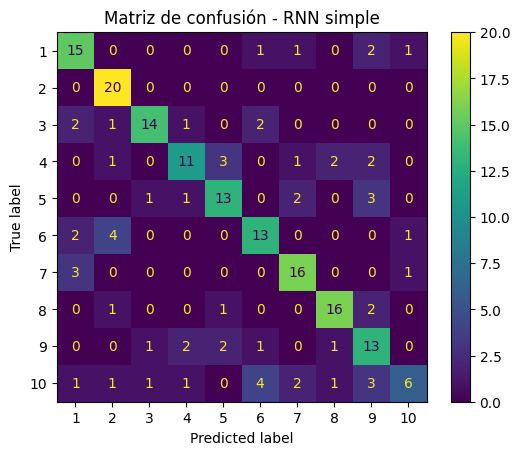

In [18]:
etiquetas = list(range(1, 11))
matriz_confusion = confusion_matrix(y_test_genero, y_pred_genero, labels=etiquetas)
disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz_confusion,
    display_labels=etiquetas,
)
disp.plot()
plt.title("Matriz de confusión - RNN simple")
plt.show()

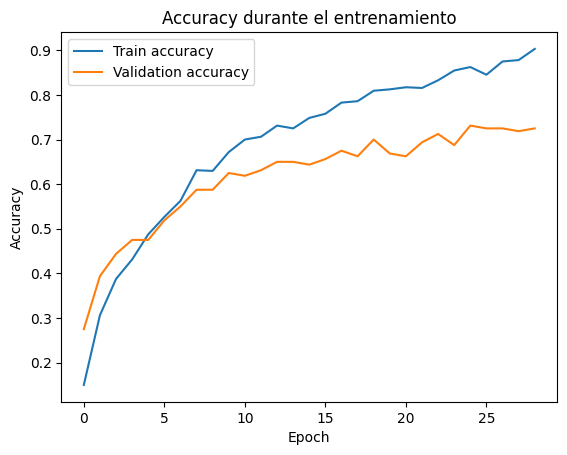

In [19]:
plt.plot(history.history["accuracy"], label="Train accuracy")
plt.plot(history.history["val_accuracy"], label="Validation accuracy")
plt.title("Accuracy durante el entrenamiento")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

**Conclusión**: El accuracy de entrenamiento sube de forma continua y en la época 29 ronda el 0,90, mientras el de validación, a partir de la época 16, se mueve entre 0,66 y 0,73 y deja de acompañar al entrenamiento. Esa separación indica sobreajuste. EarlyStopping corta en la época 29 y recupera los pesos de la época 19, la de menor pérdida de validación (0,86), con un accuracy de validación de 0,70.

**Conclusión final**: La RNN simple sobre secuencias de fragmentos de 3 s (df_macro, sin features de 30 s) alcanza un 68,5 % de accuracy y un F1 macro de 0,68 en las 200 canciones de prueba. El rendimiento es desigual entre clases: en el classification report destacan las clases 2 y 8 (F1 0,83 y 0,80) y quedan más bajas las clases 10, 9 y 4 (F1 0,41, 0,58 y 0,61). La clase 10 tiene además un recall de 0,30. La GRU del grupo, sobre secuencias del mismo tipo, llega al 72 % de accuracy y a un F1 macro de 0,72.